# How big is the fBVOC prescription artefact in PD, and does it depend on the land cover?

**Why this notebook.** Prescribing the BVOC emissions (MEGAN off, 2001–2014 climatology) raises SOA by about +3 % by itself (`fbvoc_prescription_artefact.ipynb`). The replay test traced this to using a **climatology** (`fbvoc_artefact_causes.ipynb`, H5). The BVOC effect is therefore measured with a **matched baseline** (design B, user 2026-10-30). Its one extra assumption is tested here with a short run, **LCC_PD_fBVOClccPD** (LCC land, its own LCC_PD emissions prescribed, 2000–2002; script `cases-scripts/14e-…`).

**Notation.** `art(land)` = run with its own emissions prescribed − the same run with interactive MEGAN.

| Key | Contrast | What it measures |
|---|---|---|
| **art_CTRL** | CTRL_PD_fBVOCctrlPD − CTRL_PD | artefact on CTRL land |
| **art_LCC** | LCC_PD_fBVOClccPD − LCC_PD | artefact on LCC land |
| **δ_PD** | art_LCC − art_CTRL | **how much the artefact depends on the land cover** |
| **BVOC_B** | (LCC_PD − LCC_PD_fBVOCctrlPD) + art_CTRL | PD BVOC effect, design B (matched baseline) |
| **BVOC_A** | LCC_PD_fBVOClccPD − LCC_PD_fBVOCctrlPD | PD BVOC effect, design A (prescribed pair) |
| **C** | LCC_PD − LCC_PD_fBVOCctrlPD | uncorrected `BVOC_PD` (for reference) |

**Key identity.** BVOC_A − BVOC_B = δ_PD (exact for absolute changes, first order for % changes). Design B is right if δ_PD is small compared with BVOC_B.

**How to read it (decision rule, proposed; SOA_cb, Global and 45–90°N):**

- R = |δ_PD| / |BVOC_B|.
- **R < 0.25** → B is adequate; no design-A runs for FUT.
- **R > 0.5** → the artefact depends on the land; design A in FUT is worth its 2 runs (LCC_FUT rerun with HR_BVOC_ALL + LCC_FUT_fBVOClccFUT).
- **In between** → judgement, look at the bands and years.

**Caveats.**

- Only 2 comparison years (2001–2002; 2000 dropped as spin-up). All 5 runs are nudged to the same winds and pressure, so most weather noise cancels in δ (b).
- The climatology ≠ the actual 2001–2002 emissions. That part appears in both art_LCC and art_CTRL and should cancel in δ (b).
- δ_PD from 2001–2002 is assumed to hold for 2001–2014.
- **All five runs must be from the new (CO₂-fix) chain.** The notebook checks each file's `casename` against the auto-launcher's state.

Outputs: `how_big_artefact_is_PD_outputs/` (`figures/`, `tables/`).

In [1]:
import os, sys
from pathlib import Path
import numpy as np, pandas as pd, xarray as xr
import matplotlib.pyplot as plt

REPO = Path('/cluster/home/adelez/BOREAL-FOREST-EXPANSION')
sys.path.insert(0, str(REPO / 'src'))
from boreal_forest_expansion.plotting import forcing_maps as fm

PROC = fm.POSTPROCESSED_DIR
PROC_OLD = PROC / '2001-2014-all-bvoc-pre-co2-fix'   # test-mode stand-ins (e.g. CTRL_PD_fBVOCctrlPD_HR) live here
STATE = Path('/cluster/work/users/adelez/auto-launch')   # <script>.case = new-chain case names
OUT = Path(os.environ.get('ARTEFACT_PD_OUT', 'how_big_artefact_is_PD_outputs'))
for sub in ('figures', 'tables'):
    (OUT / sub).mkdir(parents=True, exist_ok=True)

# key: (alias, auto-launch script)
RUNS = {'ctrl': ('CTRL_PD', '13a'), 'lcc': ('LCC_PD', '14a'), 'ctrl_f': ('CTRL_PD_fBVOCctrlPD', '14c'),
        'lcc_fc': ('LCC_PD_fBVOCctrlPD', '14b'), 'lcc_fl': ('LCC_PD_fBVOClccPD', '14e')}
# Testing only: ARTEFACT_PD_TEST=<alias> stands in for LCC_PD_fBVOClccPD and allows old-chain files
STANDIN = os.environ.get('ARTEFACT_PD_TEST')
if STANDIN:
    RUNS['lcc_fl'] = (STANDIN, None)
    print(f'!!! TEST MODE: lcc_fl = {STANDIN}, old-chain files allowed. These numbers are NOT the result !!!')
ALIAS = {k: a for k, (a, _) in RUNS.items()}

def procdir(alias):
    # folder of the processed files of alias: the stand-in comes from the old-chain archive folder
    return PROC_OLD if STANDIN and alias == STANDIN else PROC

def span(alias, cls='SOA'):
    # (first, last) year of the processed file alias/cls; None if there is none
    f = sorted(procdir(alias).glob(f'{alias}_atm_{cls}_*-*.nc'))
    if not f:
        return None
    y0, y1 = f[0].stem.rsplit('_', 1)[1].split('-')
    return int(y0), int(y1)

rows = []
for k, (alias, script) in RUNS.items():
    sp = span(alias)
    expected = (STATE / f'{script}.case').read_text().strip() if script and (STATE / f'{script}.case').exists() else None
    found = xr.open_dataset(procdir(alias) / fm.filename(alias, 'SOA', *sp).name).attrs.get('casename') if sp else None
    ok = sp is not None and (STANDIN is not None or (expected is not None and found == expected))
    rows.append(dict(key=k, alias=alias, processed_years=sp, case_in_file=found, new_chain_case=expected, ok=ok))
STATUS = pd.DataFrame(rows).set_index('key')
READY = bool(STATUS['ok'].all())
YEARS = list(range(*(lambda s: (s[0], s[1] + 1))(span(ALIAS['lcc_fl'])))) if READY else []
if READY:
    for k in RUNS:
        y0, y1 = STATUS.loc[k, 'processed_years']
        READY &= y0 <= YEARS[0] and y1 >= YEARS[-1]
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 70)
display(STATUS)
print('READY:', READY, '| comparison years:', YEARS if READY else 'pending')
if not READY:
    print('Pending: every run must be processed and come from the new chain (case_in_file = new_chain_case).')

,alias,processed_years,case_in_file,new_chain_case,ok
key,,,,,
ctrl,CTRL_PD,"(2001, 2014)",NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029,NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20261029,True
lcc,LCC_PD,"(2001, 2014)",NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028,NF2000norbc_tropstratchem_nudg_lcc_f19_f19-20261028,True
ctrl_f,CTRL_PD_fBVOCctrlPD,"(2001, 2014)",NF2000norbc_tropstratchem_nudg_ctrl_fBVOCctrlPD_f19_f19-20261031,NF2000norbc_tropstratchem_nudg_ctrl_fBVOCctrlPD_f19_f19-20261031,True
lcc_fc,LCC_PD_fBVOCctrlPD,"(2001, 2014)",NF2000norbc_tropstratchem_nudg_lcc_fBVOCctrlPD_f19_f19-20261031,NF2000norbc_tropstratchem_nudg_lcc_fBVOCctrlPD_f19_f19-20261031,True
lcc_fl,LCC_PD_fBVOClccPD,"(2001, 2002)",NF2000norbc_tropstratchem_nudg_lcc_fBVOClccPD_f19_f19-20261031,NF2000norbc_tropstratchem_nudg_lcc_fBVOClccPD_f19_f19-20261031,True


READY: True | comparison years: [2001, 2002]


## 1. Yearly fields
Calendar-year means weighted by month length (`fm.annual_mean`). 3-D fields: lowest model level. `SOA_cb` = column burden of interstitial SOA (A1 + NA). Same variable set as `fbvoc_prescription_artefact.ipynb`.

In [2]:
def open_years(alias, cls, years):
    y0, y1 = span(alias, cls)
    ds = xr.open_dataset(procdir(alias) / fm.filename(alias, cls, y0, y1).name)
    ds = ds.isel(time=ds['time'].dt.year.isin(years).values)
    missing = sorted(set(years) - set(np.unique(ds['time'].dt.year.values)))
    if missing:
        raise ValueError(f'{alias} {cls}: years {missing} missing')
    return ds

def ym(v, lev=None, scale=1.0):
    def f(ds):
        da = ds[v] if lev is None else ds[v].isel(lev=lev)
        return fm.annual_mean(da, ds) * scale
    return f

# name: (class, yearly field, units, report relative change [%]?)
VARS = {
    'SFISOP':     ('BVOC', ym('SFISOP'), 'kg m-2 s-1', True),
    'SFMTERP':    ('BVOC', ym('SFMTERP'), 'kg m-2 s-1', True),
    'cb_ISOP':    ('BVOC', ym('cb_ISOP'), 'kg m-2', True),
    'cb_MTERP':   ('BVOC', ym('cb_MTERP'), 'kg m-2', True),
    'cb_SOA_LV':  ('SOA', ym('cb_SOA_LV'), 'kg m-2', True),
    'cb_SOA_SV':  ('SOA', ym('cb_SOA_SV'), 'kg m-2', True),
    'SOA_cb':     ('SOA', ym('SOA_cb', scale=1e6), 'mg m-2', True),
    'N_AER_sfc':  ('SOA', ym('N_AER', lev=-1), 'cm-3', True),
    'OH_sfc':     ('CHEM', ym('OH', lev=-1), 'mol mol-1', True),
    'CDNC_incld': ('CLOUDPROP', lambda ds: fm.yearly_field(ds, 'ACTNL_incld'), 'cm-3', True),
    'LWP':        ('CLOUDPROP', lambda ds: fm.yearly_field(ds, 'TGCLDLWP_gm2'), 'g m-2', True),
    'NET_toa':    ('RADIATIVE', ym('NET_toa'), 'W m-2', False),
}

def fields(alias, years):
    out, opened = {}, {}
    for name, (cls, fn, units, rel) in VARS.items():
        try:
            if cls not in opened:
                opened[cls] = open_years(alias, cls, years)
            out[name] = fn(opened[cls]).load()
        except (KeyError, TypeError, ValueError, FileNotFoundError) as e:
            print(f'  {alias}: {name} skipped ({type(e).__name__}: {e})')
    return out

if READY:
    F = {k: fields(a, YEARS) for k, a in ALIAS.items()}
    print({k: len(v) for k, v in F.items()})
else:
    print('pending: runs not ready (see the status table)')

{'ctrl': 12, 'lcc': 12, 'ctrl_f': 12, 'lcc_fc': 12, 'lcc_fl': 12}


## 2. Changes by latitude band
Area-weighted (cos lat) band means of each year. A change is case1 − case2 in % of case2 (NET_toa: absolute, W m⁻²); the tables show the mean over the years. δ_PD and BVOC_B are sums/differences of % changes, i.e. first order. **closure** = BVOC_A − BVOC_B − δ_PD (≈ 0; it shows the size of the first-order error).

The emission rows (SFISOP, SFMTERP) of art_LCC and art_CTRL are not exactly 0: the prescribed runs get the 2001–2014 climatology, the interactive runs the actual 2001–2002 emissions.

In [3]:
BANDS = {'Global': (-90, 90), '90–30°S': (-90, -30), '30°S–30°N': (-30, 30), '30–45°N': (30, 45),
         '45–60°N': (45, 60), '60–90°N': (60, 90), '45–90°N': (45, 90)}
BAR_BANDS = ['Global', '90–30°S', '30°S–30°N', '45–60°N', '60–90°N']
PAIRS = {'art_CTRL': ('ctrl_f', 'ctrl'), 'art_LCC': ('lcc_fl', 'lcc'), 'C': ('lcc', 'lcc_fc'),
         'BVOC_A': ('lcc_fl', 'lcc_fc')}
ORDER = ['art_CTRL', 'art_LCC', 'δ_PD', 'C', 'BVOC_B', 'BVOC_A', 'closure']

def change(c1, c2, var, lo, hi):
    # yearly band-mean change case1 − case2: % of case2 (relative variables) or absolute
    a = fm.area_weighted_mean(F[c1][var], lat_min=lo, lat_max=hi)
    b = fm.area_weighted_mean(F[c2][var], lat_min=lo, lat_max=hi)
    return (100 * (a - b) / b if VARS[var][3] else a - b).values

CH = {}   # (contrast, variable, band) -> yearly values
if READY:
    for var in VARS:
        if not all(var in F[k] for k in F):
            continue
        for band, (lo, hi) in BANDS.items():
            x = {key: change(c1, c2, var, lo, hi) for key, (c1, c2) in PAIRS.items()}
            x['δ_PD'] = x['art_LCC'] - x['art_CTRL']
            x['BVOC_B'] = x['C'] + x['art_CTRL']
            x['closure'] = x['BVOC_A'] - x['BVOC_B'] - x['δ_PD']
            for key in ORDER:
                CH[(key, var, band)] = x[key]
    tab = pd.DataFrame([dict(variable=v, contrast=k, band=b, mean=x.mean(), **{str(y): val for y, val in zip(YEARS, x)})
                        for (k, v, b), x in CH.items()])
    T = tab.pivot_table(index=['variable', 'contrast'], columns='band', values='mean', sort=False)[list(BANDS)]
    T.round(3).to_csv(OUT / 'tables' / 'changes_by_band.csv')
    tab.to_csv(OUT / 'tables' / 'changes_by_band_long.csv', index=False)
    pd.set_option('display.max_rows', 300)
    print(f'Saved {OUT}/tables/changes_by_band.csv')
    display(T.loc[['SFISOP', 'SFMTERP', 'cb_ISOP', 'cb_MTERP', 'cb_SOA_LV', 'cb_SOA_SV', 'SOA_cb', 'N_AER_sfc']].round(2))
else:
    print('pending')

Saved how_big_artefact_is_PD_outputs/tables/changes_by_band.csv


band                Global  90–30°S  30°S–30°N  30–45°N  45–60°N  60–90°N  45–90°N
variable  contrast                                                                
SFISOP    art_CTRL   -0.12    -2.02       0.01    -4.68     6.51     5.73     6.06
          art_LCC     0.84     0.93       1.00    -4.63     5.68     3.21     5.17
          δ_PD        0.96     2.95       0.98     0.04    -0.83    -2.52    -0.89
          C          -0.92    -1.23      -1.13     5.04    -1.38    -2.48    -1.48
          BVOC_B     -1.04    -3.26      -1.11     0.36     5.13     3.25     4.58
          BVOC_A     -0.09    -0.52      -0.14    -0.12     3.40    -0.12     3.06
          closure    -0.01    -0.22      -0.01    -0.52    -0.91    -0.85    -0.62
SFMTERP   art_CTRL    0.19     0.93       0.10    -3.04     4.28     5.06     4.32
          art_LCC     0.93     3.49       0.94    -2.84     3.32     3.08     3.21
          δ_PD        0.74     2.56       0.85     0.20    -0.96    -1.98    -1.11
          C          -1.02    -3.91      -1.07     2.70    -4.57     9.68    -2.35
          BVOC_B     -0.84    -2.99      -0.98    -0.33    -0.29    14.74     1.96
          BVOC_A     -0.11    -0.67      -0.14    -0.36    -1.55    12.96     0.70
          closure    -0.01    -0.25      -0.01    -0.23    -0.30     0.20    -0.15
cb_ISOP   art_CTRL    0.21    -2.44       0.17     0.23    22.87    26.92    22.20
          art_LCC     1.89     0.17       1.85     0.81    19.66    24.26    19.53
          δ_PD        1.68     2.61       1.69     0.58    -3.22    -2.65    -2.67
          C          -1.87     0.15      -1.86     0.26    -8.47   -16.05    -9.93
          BVOC_B     -1.66    -2.29      -1.69     0.49    14.40    10.86    12.27
          BVOC_A     -0.02    -0.19      -0.04    -0.26     7.02     2.73     6.35
          closure    -0.04    -0.51      -0.03    -1.33    -4.16    -5.48    -3.25
cb_MTERP  art_CTRL    0.71     2.41       0.56     0.03    12.19    10.96    11.78
          art_LCC     1.97     4.19       1.85     0.53    10.49     9.46    10.14
          δ_PD        1.26     1.79       1.29     0.50    -1.70    -1.49    -1.64
          C          -1.99    -4.10      -1.91    -0.76   -10.12     9.39    -6.46
          BVOC_B     -1.28    -1.69      -1.36    -0.73     2.08    20.34     5.32
          BVOC_A     -0.06    -0.34      -0.10    -0.62    -0.92    19.46     2.94
          closure    -0.04    -0.43      -0.04    -0.39    -1.30     0.61    -0.74
cb_SOA_LV art_CTRL    4.60     0.32       5.11     3.73    11.87     6.05     9.83
          art_LCC     5.17     0.22       5.82     3.59    10.89     5.44     8.88
          δ_PD        0.57    -0.10       0.71    -0.15    -0.98    -0.60    -0.94
          C          -4.78    -0.28      -5.39    -4.16   -10.13     3.06    -5.76
          BVOC_B     -0.18     0.04      -0.27    -0.43     1.74     9.11     4.06
          BVOC_A      0.14    -0.06       0.12    -0.83    -0.40     8.61     2.60
          closure    -0.25    -0.00      -0.31    -0.25    -1.16     0.11    -0.52
cb_SOA_SV art_CTRL    3.51     0.41       4.04     4.31     4.50    -0.26     2.58
          art_LCC     3.95     0.32       4.61     3.59     4.26    -0.77     2.21
          δ_PD        0.45    -0.09       0.57    -0.72    -0.25    -0.52    -0.36
          C          -3.73    -0.45      -4.31    -4.08    -3.74     2.06    -1.48
          BVOC_B     -0.22    -0.03      -0.27     0.22     0.76     1.80     1.09
          BVOC_A      0.08    -0.13       0.11    -0.68     0.32     1.26     0.69
          closure    -0.15    -0.00      -0.20    -0.18    -0.19    -0.02    -0.04
SOA_cb    art_CTRL    2.59     2.66       2.63     1.55     3.04     3.45     3.19
          art_LCC     3.64     4.01       3.86     1.81     2.86     3.16     2.97
          δ_PD        1.06     1.35       1.23     0.26    -0.18    -0.29    -0.22
          C          -3.89    -4.66      -3.99    -2.29    -3.26    -3.25    -3.26
          BVOC_B

### 2b. Clouds [%], net TOA radiation [W m⁻²] and year by year (SOA_cb)

In [4]:
if READY:
    display(T.loc[['OH_sfc', 'CDNC_incld', 'LWP', 'NET_toa']].round(3))
    for band in ('Global', '45–90°N'):
        print(f'--- SOA_cb, {band}')
        for k in ORDER:
            print(f'  {k:9s}', '  '.join(f'{y}: {v:+.2f}' for y, v in zip(YEARS, CH[(k, "SOA_cb", band)])),
                  f'  mean {CH[(k, "SOA_cb", band)].mean():+.2f} %')
else:
    print('pending')

band                 Global  90–30°S  30°S–30°N  30–45°N  45–60°N  60–90°N  45–90°N
variable   contrast                                                                
OH_sfc     art_CTRL  -0.108   -0.400     -0.141    0.221   -0.267    0.043   -0.181
           art_LCC   -0.213   -0.596     -0.255    0.195   -0.401    0.126   -0.256
           δ_PD      -0.104   -0.196     -0.114   -0.026   -0.134    0.082   -0.075
           C          0.195    0.560      0.245   -0.148    0.267   -0.544    0.039
           BVOC_B     0.087    0.160      0.104    0.073   -0.001   -0.501   -0.141
           BVOC_A    -0.018   -0.040     -0.010    0.046   -0.141   -0.420   -0.218
           closure   -0.000   -0.004     -0.001   -0.000   -0.006   -0.002   -0.002
CDNC_incld art_CTRL   0.143    0.028      0.013    0.348    0.861    0.785    0.838
           art_LCC    0.607    0.471      0.667    0.095    0.951    0.763    0.892
           δ_PD       0.464    0.443      0.654   -0.253    0.090   -0.022    0.054
           C         -0.532   -0.317     -0.691   -0.016   -0.752   -0.416   -0.650
           BVOC_B    -0.389   -0.289     -0.678    0.332    0.109    0.370    0.188
           BVOC_A     0.071    0.152     -0.029    0.077    0.192    0.344    0.236
           closure   -0.004   -0.002     -0.005   -0.001   -0.007   -0.004   -0.006
LWP        art_CTRL   0.095    0.073      0.118    0.259    0.009   -0.069   -0.021
           art_LCC    0.046   -0.103      0.147    0.068    0.131   -0.078    0.047
           δ_PD      -0.049   -0.176      0.029   -0.191    0.123   -0.009    0.068
           C         -0.067    0.068     -0.173   -0.075   -0.144    0.132   -0.033
           BVOC_B     0.028    0.141     -0.055    0.183   -0.135    0.063   -0.054
           BVOC_A    -0.021   -0.035     -0.026   -0.007   -0.013    0.054    0.014
           closure   -0.000   -0.000     -0.000   -0.000   -0.000   -0.000    0.000
NET_toa    art_CTRL  -0.053   -0.039     -0.035   -0.169   -0.079   -0.023   -0.054
           art_LCC   -0.070    0.048     -0.140   -0.003   -0.081   -0.070   -0.076
           δ_PD      -0.017    0.087     -0.105    0.166   -0.001   -0.047   -0.022
           C          0.072   -0.005      0.147   -0.096    0.078    0.051    0.066
           BVOC_B     0.020   -0.044      0.112   -0.265   -0.001    0.028    0.012
           BVOC_A     0.003    0.044      0.007   -0.099   -0.003   -0.019   -0.010
           closure    0.000    0.000      0.000    0.000    0.000    0.000    0.000

--- SOA_cb, Global
  art_CTRL  2001: +2.20  2002: +2.98   mean +2.59 %
  art_LCC   2001: +3.04  2002: +4.25   mean +3.64 %
  δ_PD      2001: +0.85  2002: +1.26   mean +1.06 %
  C         2001: -3.14  2002: -4.64   mean -3.89 %
  BVOC_B    2001: -0.94  2002: -1.66   mean -1.30 %
  BVOC_A    2001: -0.19  2002: -0.59   mean -0.39 %
  closure   2001: -0.10  2002: -0.20   mean -0.15 %
--- SOA_cb, 45–90°N
  art_CTRL  2001: +2.96  2002: +3.41   mean +3.19 %
  art_LCC   2001: +1.41  2002: +4.52   mean +2.97 %
  δ_PD      2001: -1.55  2002: +1.11   mean -0.22 %
  C         2001: -1.40  2002: -5.12   mean -3.26 %
  BVOC_B    2001: +1.57  2002: -1.71   mean -0.07 %
  BVOC_A    2001: -0.01  2002: -0.83   mean -0.42 %
  closure   2001: -0.02  2002: -0.23   mean -0.13 %


## 3. Verdict
Rule in the header: R = |δ_PD| / |BVOC_B| for SOA_cb; R < 0.25 → design B adequate, R > 0.5 → design A in FUT worth it. The year-to-year spread of δ (2 values) is shown too: if the two years disagree in sign, δ is within the noise.

In [5]:
if not READY:
    print('pending: LCC_PD_fBVOClccPD (or another new-chain run) not processed yet. Nothing to conclude.')
else:
    lines, Rs = [], []
    for band in ('Global', '45–90°N'):
        d, bb, ba = (CH[(k, 'SOA_cb', band)] for k in ('δ_PD', 'BVOC_B', 'BVOC_A'))
        R = abs(d.mean()) / abs(bb.mean()); Rs.append(R)
        lines.append(f'{band:8s} SOA_cb: δ_PD = {d.mean():+.2f} % (years ' + ', '.join(f'{v:+.2f}' for v in d) +
                     f'), BVOC_B = {bb.mean():+.2f} %, BVOC_A = {ba.mean():+.2f} %  -> R = {R:.2f}')
    Rmax = max(Rs)
    verdict = ('DESIGN B ADEQUATE: the artefact hardly depends on the land cover' if Rmax < 0.25 else
               'ARTEFACT DEPENDS ON THE LAND: design A in FUT is worth it' if Rmax > 0.5 else
               'IN BETWEEN: look at the bands and years before deciding')
    if STANDIN:
        verdict = 'TEST MODE, NO VERDICT'
    print('\n'.join(lines)); print('\n' + verdict)
    (OUT / 'tables' / 'verdict.txt').write_text('\n'.join(lines + ['', verdict]) + '\n')

Global   SOA_cb: δ_PD = +1.06 % (years +0.85, +1.26), BVOC_B = -1.30 %, BVOC_A = -0.39 %  -> R = 0.81
45–90°N  SOA_cb: δ_PD = -0.22 % (years -1.55, +1.11), BVOC_B = -0.07 %, BVOC_A = -0.42 %  -> R = 2.98

ARTEFACT DEPENDS ON THE LAND: design A in FUT is worth it


## 4. Figures
### 4a. SOA burden and aerosol number by latitude band

findfont: Failed to find font weight semibold, now using 700.


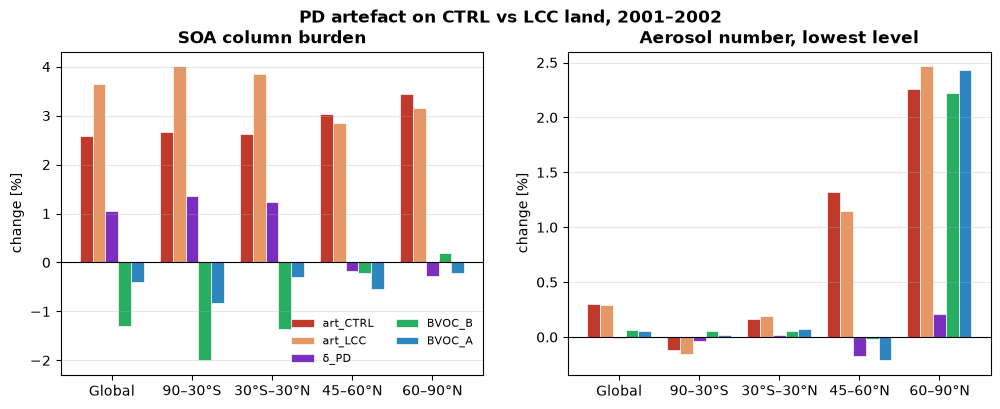

In [6]:
# Colours: project palette (src/boreal_forest_expansion/plotting/palette.py, user 2026-11-03)
COLORS = {'art_CTRL': '#BC423E', 'art_LCC': '#DE7A3A', 'δ_PD': '#9A4A84', 'BVOC_B': '#5D9A92', 'BVOC_A': '#2C3990'}
if READY:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, var, title in zip(axes, ['SOA_cb', 'N_AER_sfc'], ['SOA column burden', 'Aerosol number, lowest level']):
        shown = [k for k in COLORS if (k, var, 'Global') in CH]
        w = 0.8 / max(len(shown), 1)
        for i, k in enumerate(shown):
            ax.bar(np.arange(len(BAR_BANDS)) + (i - (len(shown) - 1) / 2) * w,
                   [CH[(k, var, b)].mean() for b in BAR_BANDS], w, color=COLORS[k], label=k,
                   edgecolor='white', linewidth=0.5)
        ax.axhline(0, color='k', lw=0.8)
        ax.set_xticks(np.arange(len(BAR_BANDS)), BAR_BANDS)
        ax.set_ylabel('change [%]'); ax.set_title(title, fontweight='semibold'); ax.grid(axis='y', alpha=0.3)
    axes[0].legend(fontsize=8, ncol=2, frameon=False)
    fig.suptitle(f'PD artefact on CTRL vs LCC land, {YEARS[0]}–{YEARS[-1]}' + ('  [TEST MODE]' if STANDIN else ''),
                 fontweight='bold')
    fig.savefig(OUT / 'figures' / 'artefact_pd_bars_by_band.png', dpi=200, bbox_inches='tight')
else:
    print('pending')

### 4b. Zonal mean SOA burden change
If δ_PD is a land effect it should peak near the changed land (46–82°N); a flat δ ≈ 0 supports design B.

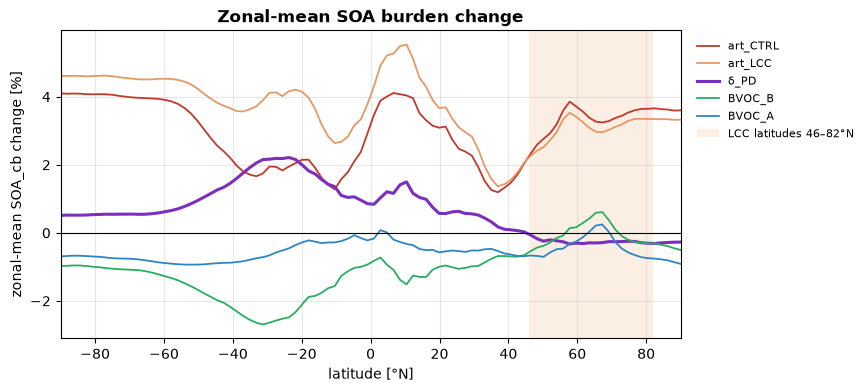

In [7]:
def zonal_pct(c1, c2, var='SOA_cb'):
    a = F[c1][var].mean('year').mean('lon'); b = F[c2][var].mean('year').mean('lon')
    return 100 * (a - b) / b

if READY:
    z = {k: zonal_pct(*PAIRS[k]) for k in PAIRS}
    z['δ_PD'] = z['art_LCC'] - z['art_CTRL']; z['BVOC_B'] = z['C'] + z['art_CTRL']
    fig, ax = plt.subplots(figsize=(8, 4))
    for k, col in COLORS.items():
        ax.plot(z[k]['lat'], z[k], color=col, lw=2.2 if k == 'δ_PD' else 1.3, label=k)
    ax.axhline(0, color='k', lw=0.8); ax.axvspan(46, 82, color='#f5cba7', alpha=0.3, lw=0, label='LCC latitudes 46–82°N')
    ax.set_xlabel('latitude [°N]'); ax.set_ylabel('zonal-mean SOA_cb change [%]'); ax.set_xlim(-90, 90)
    ax.legend(fontsize=8, frameon=False, loc='upper left', bbox_to_anchor=(1.01, 1)); ax.grid(alpha=0.3)
    ax.set_title('Zonal-mean SOA burden change' + ('  [TEST MODE]' if STANDIN else ''), fontweight='semibold')
    fig.savefig(OUT / 'figures' / 'artefact_pd_zonal_soa.png', dpi=200, bbox_inches='tight')
else:
    print('pending')

## 5. What next
- **Design B adequate** → keep the matched baseline everywhere: PD BVOC = C + art_CTRL; FUT BVOC = (LCC_FUT − LCC_FUT_fBVOC*) + art_FUT, with art_FUT = CTRL_FUT_fBVOCctrlFUT − CTRL_FUT (script 24e, auto-launched with LCC_FUT_fBVOCctrlFUT).
- **Artefact depends on the land** → design A in FUT: rerun LCC_FUT with `cam_diagnostics HR_BVOC_ALL`, build its climatology, run LCC_FUT_fBVOClccFUT (needs the user's OK).
- **In between** → extend LCC_PD_fBVOClccPD by a few years (it restarts from 2003-01-01) to reduce the noise.